# Electricity Demand Patterns in Great Britain (2024)

This notebook investigates temporal patterns in electricity demand across Great Britain using the 2024 Historic Demand Data published by the National Energy System Operator (NESO).

The analysis examines monthly and seasonal variation, weekday versus weekend demand, and typical daily demand profiles to identify patterns relevant to electricity system planning.

### Analysis Workflow

1. Load the dataset and prepare date variables.
2. Create time-based features for analysis.
3. Analyse monthly and seasonal electricity demand.
4. Compare weekday and weekend demand.
5. Investigate typical daily demand profiles.

In [59]:
import pandas as pd

### Load the Dataset

The 2024 NESO Historic Demand Data is loaded from the project's raw data directory into a pandas DataFrame for analysis.

In [60]:
df = pd.read_csv("../data/raw/demanddata_2024.csv")

In [61]:
df.head()

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,TSD,ENGLAND_WALES_DEMAND,EMBEDDED_WIND_GENERATION,EMBEDDED_WIND_CAPACITY,EMBEDDED_SOLAR_GENERATION,EMBEDDED_SOLAR_CAPACITY,NON_BM_STOR,...,IFA_FLOW,IFA2_FLOW,BRITNED_FLOW,MOYLE_FLOW,EAST_WEST_FLOW,NEMO_FLOW,NSL_FLOW,ELECLINK_FLOW,VIKING_FLOW,GREENLINK_FLOW
0,01-JAN-2024,1,21783,23466,19539,2804,6488,0,16793,0,...,417,-4,666,-179,-92,905,62,998,572,0
1,01-JAN-2024,2,22521,24103,20286,2834,6488,0,16793,0,...,430,-4,661,-60,-8,901,-15,998,575,0
2,01-JAN-2024,3,22194,24754,20070,2868,6488,0,16793,0,...,834,-4,661,-118,-1,807,-396,997,422,0
3,01-JAN-2024,4,21510,24505,19424,2901,6488,0,16793,0,...,839,-4,661,-270,-84,803,-473,997,401,0
4,01-JAN-2024,5,20619,23977,18674,2933,6488,0,16793,0,...,53,-5,661,-340,-103,537,-856,998,28,0


In [62]:
df["SETTLEMENT_DATE"] = pd.to_datetime(
    df["SETTLEMENT_DATE"],
    format="%d-%b-%Y"
)

## 2. Feature Engineering

Additional time-based features will be created from the settlement date and settlement period to support analysis of daily, weekly, monthly, and seasonal electricity demand patterns.

In [63]:
df["DATETIME"] = (
    df["SETTLEMENT_DATE"]
    + pd.to_timedelta((df["SETTLEMENT_PERIOD"] - 1) * 30, unit="m")
)

In [64]:
df[["SETTLEMENT_DATE", "SETTLEMENT_PERIOD", "DATETIME", "ND"]].head()

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,DATETIME,ND
0,2024-01-01,1,2024-01-01 00:00:00,21783
1,2024-01-01,2,2024-01-01 00:30:00,22521
2,2024-01-01,3,2024-01-01 01:00:00,22194
3,2024-01-01,4,2024-01-01 01:30:00,21510
4,2024-01-01,5,2024-01-01 02:00:00,20619


### Settlement Period Validation

A standard day contains 48 half-hour settlement periods. The dataset contains settlement periods greater than 48, so these observations are investigated before further time-based feature engineering.

In [65]:
df["SETTLEMENT_PERIOD"].value_counts().sort_index()

SETTLEMENT_PERIOD
1     366
2     366
3     366
4     366
5     366
6     366
7     366
8     366
9     366
10    366
11    366
12    366
13    366
14    366
15    366
16    366
17    366
18    366
19    366
20    366
21    366
22    366
23    366
24    366
25    366
26    366
27    366
28    366
29    366
30    366
31    366
32    366
33    366
34    366
35    366
36    366
37    366
38    366
39    366
40    366
41    366
42    366
43    366
44    366
45    366
46    366
47    365
48    365
49      1
50      1
Name: count, dtype: int64

In [66]:
df[df["SETTLEMENT_PERIOD"] > 48][
    ["SETTLEMENT_DATE", "SETTLEMENT_PERIOD", "ND"]
]

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND
14446,2024-10-27,49,21183
14447,2024-10-27,50,20226


In [67]:
df.groupby("SETTLEMENT_DATE").size().sort_values().head()

SETTLEMENT_DATE
2024-03-31    46
2024-09-05    48
2024-09-04    48
2024-09-03    48
2024-09-02    48
dtype: int64

**Finding:** Most days contain 48 half-hour settlement periods. However, 31 March 2024 contains 46 periods and 27 October 2024 contains 50 periods. These dates correspond to the UK daylight-saving clock changes, when the clocks move forward and backward respectively.

In [68]:
df[df["SETTLEMENT_PERIOD"] > 48][
    ["SETTLEMENT_DATE", "SETTLEMENT_PERIOD", "DATETIME", "ND"]
]

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,DATETIME,ND
14446,2024-10-27,49,2024-10-28 00:00:00,21183
14447,2024-10-27,50,2024-10-28 00:30:00,20226


In [69]:
df["DAY_OF_WEEK"] = df["SETTLEMENT_DATE"].dt.day_name()

In [70]:
df[["SETTLEMENT_DATE", "DAY_OF_WEEK"]].head()

,SETTLEMENT_DATE,DAY_OF_WEEK
0,2024-01-01,Monday
1,2024-01-01,Monday
2,2024-01-01,Monday
3,2024-01-01,Monday
4,2024-01-01,Monday


In [71]:
df["IS_WEEKEND"] = df["SETTLEMENT_DATE"].dt.dayofweek >= 5

In [72]:
df[
    ["SETTLEMENT_DATE", "DAY_OF_WEEK", "IS_WEEKEND"]
].head()

,SETTLEMENT_DATE,DAY_OF_WEEK,IS_WEEKEND
0,2024-01-01,Monday,False
1,2024-01-01,Monday,False
2,2024-01-01,Monday,False
3,2024-01-01,Monday,False
4,2024-01-01,Monday,False


In [73]:
df["MONTH"] = df["SETTLEMENT_DATE"].dt.month_name()

In [74]:
df[["SETTLEMENT_DATE", "MONTH"]].head()

,SETTLEMENT_DATE,MONTH
0,2024-01-01,January
1,2024-01-01,January
2,2024-01-01,January
3,2024-01-01,January
4,2024-01-01,January


In [75]:
df["MONTH_NUM"] = df["SETTLEMENT_DATE"].dt.month

In [76]:
season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
}

df["SEASON"] = df["MONTH_NUM"].map(season_map)

In [77]:
df[
    ["SETTLEMENT_DATE", "DAY_OF_WEEK", "IS_WEEKEND",
     "MONTH", "MONTH_NUM", "SEASON"]
].sample(10)

,SETTLEMENT_DATE,DAY_OF_WEEK,IS_WEEKEND,MONTH,MONTH_NUM,SEASON
13602,2024-10-10,Thursday,False,October,10,Autumn
1860,2024-02-08,Thursday,False,February,2,Winter
2823,2024-02-28,Wednesday,False,February,2,Winter
8782,2024-07-02,Tuesday,False,July,7,Summer
3854,2024-03-21,Thursday,False,March,3,Spring
3976,2024-03-23,Saturday,True,March,3,Spring
11931,2024-09-05,Thursday,False,September,9,Autumn
15758,2024-11-24,Sunday,True,November,11,Autumn
2107,2024-02-13,Tuesday,False,February,2,Winter
13326,2024-10-04,Friday,False,October,10,Autumn


## 3. Exploratory Data Analysis

### Monthly Electricity Demand

The average National Demand (ND) is calculated for each month to examine seasonal patterns in electricity demand across 2024.

In [78]:
monthly_demand = (
    df.groupby(["MONTH_NUM", "MONTH"])["ND"]
    .mean()
    .reset_index()
)

monthly_demand

,MONTH_NUM,MONTH,ND
0,1,January,31808.836022
1,2,February,29526.081897
2,3,March,27902.240242
3,4,April,25210.959028
4,5,May,23120.840054
5,6,June,22103.075000
6,7,July,22822.988575
7,8,August,21699.211694
8,9,September,24307.613889
9,10,October,26696.029530


In [79]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [80]:
import matplotlib.pyplot as plt

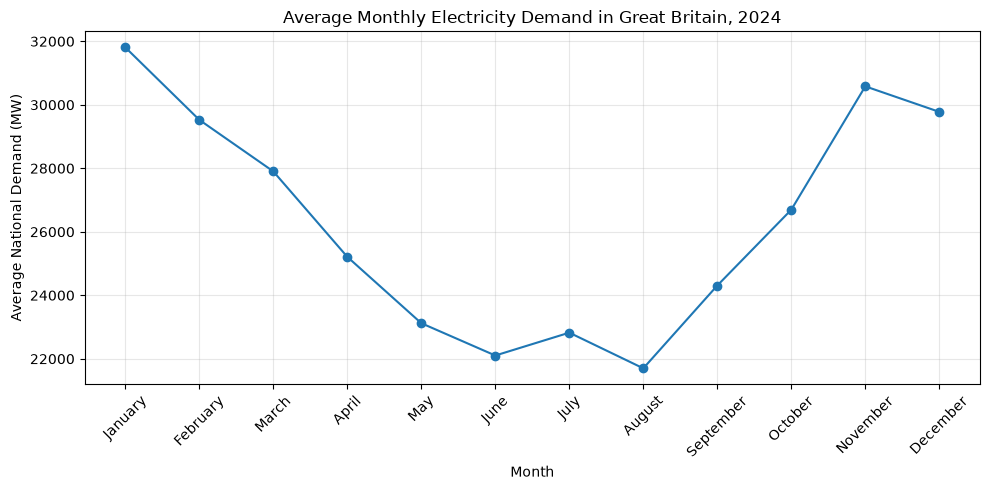

In [81]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_demand["MONTH"],
    monthly_demand["ND"],
    marker="o"
)

plt.title("Average Monthly Electricity Demand in Great Britain, 2024")
plt.xlabel("Month")
plt.ylabel("Average National Demand (MW)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Finding:** Average National Demand shows a clear seasonal pattern across 2024. Demand generally declines from January towards the summer months, with a small increase around July before reaching its lowest average level in August. Demand then rises again through autumn towards winter. January recorded the highest average demand at approximately 31,809 MW, while August recorded the lowest at approximately 21,699 MW.

### Weekday vs Weekend Electricity Demand

Average National Demand is compared between weekdays and weekends to examine whether electricity consumption patterns differ across the week.

In [82]:
weekend_demand = (
    df.groupby("IS_WEEKEND")["ND"]
    .mean()
)

weekend_demand

IS_WEEKEND
False    27199.350827
True     23987.743590
Name: ND, dtype: float64

In [83]:
weekday_avg = weekend_demand[False]
weekend_avg = weekend_demand[True]

difference = weekday_avg - weekend_avg

difference

np.float64(3211.6072372284216)

In [84]:
percentage_difference = (
    difference / weekday_avg
) * 100

percentage_difference

np.float64(11.807661358019097)

**Finding:** Average National Demand was approximately 27,199 MW on weekdays compared with 23,988 MW on weekends. Weekend demand was therefore around 3,212 MW, or 11.8%, lower than weekday demand.

### Daily Demand Profile: Weekdays vs Weekends

Average National Demand is examined across settlement periods to compare how electricity demand changes throughout the day on weekdays and weekends.

In [85]:
daily_profile = (
    df.groupby(["SETTLEMENT_PERIOD", "IS_WEEKEND"])["ND"]
    .mean()
    .reset_index()
)

daily_profile.head(10)

,SETTLEMENT_PERIOD,IS_WEEKEND,ND
0,1,False,22270.679389
1,1,True,21987.711538
2,2,False,22181.385496
3,2,True,21846.009615
4,3,False,21862.396947
5,3,True,21443.605769
6,4,False,21578.316794
7,4,True,21056.115385
8,5,False,21216.633588
9,5,True,20586.740385


In [86]:
weekday_profile = daily_profile[daily_profile["IS_WEEKEND"] == False]
weekend_profile = daily_profile[daily_profile["IS_WEEKEND"] == True]

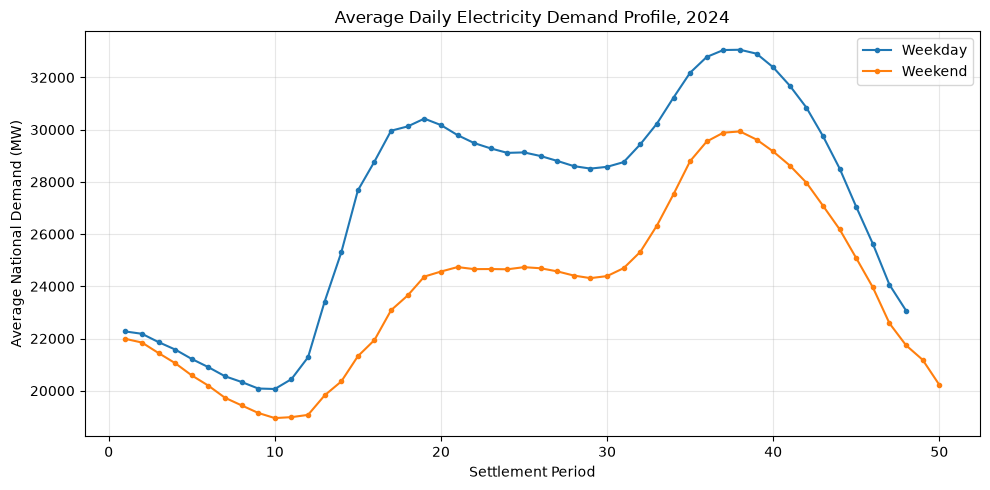

In [87]:
plt.figure(figsize=(10, 5))

plt.plot(
    weekday_profile["SETTLEMENT_PERIOD"],
    weekday_profile["ND"],
    marker="o",
    markersize=3,
    label="Weekday"
)

plt.plot(
    weekend_profile["SETTLEMENT_PERIOD"],
    weekend_profile["ND"],
    marker="o",
    markersize=3,
    label="Weekend"
)

plt.title("Average Daily Electricity Demand Profile, 2024")
plt.xlabel("Settlement Period")
plt.ylabel("Average National Demand (MW)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [88]:
weekday_peak = weekday_profile.loc[
    weekday_profile["ND"].idxmax()
]

weekend_peak = weekend_profile.loc[
    weekend_profile["ND"].idxmax()
]

weekday_peak

SETTLEMENT_PERIOD              38
IS_WEEKEND                  False
ND                   33062.515267
Name: 74, dtype: object

In [89]:
weekend_peak

SETTLEMENT_PERIOD              38
IS_WEEKEND                   True
ND                   29933.240385
Name: 75, dtype: object

**Finding:** The daily electricity demand profile shows a clear overnight decline, reaching its lowest levels in the early morning before rising sharply as the day begins. Demand increases during the morning, levels off or falls slightly during the afternoon, and rises again towards an evening peak.

Both weekday and weekend average demand profiles peak at settlement period 38 (approximately 18:30–19:00). Average demand at this period is approximately 33,063 MW on weekdays and 29,933 MW on weekends. Overall, weekday demand remains higher than weekend demand, consistent with the earlier finding that average weekend demand is approximately 11.8% lower.

### Seasonal Electricity Demand

Average National Demand is compared across seasons to examine broader seasonal variation in electricity demand during 2024.

In [90]:
seasonal_demand = (
    df.groupby("SEASON")["ND"]
    .mean()
    .reindex(["Winter", "Spring", "Summer", "Autumn"])
)

seasonal_demand

SEASON
Winter    30389.358516
Spring    25412.396919
Summer    22209.570199
Autumn    27189.325400
Name: ND, dtype: float64

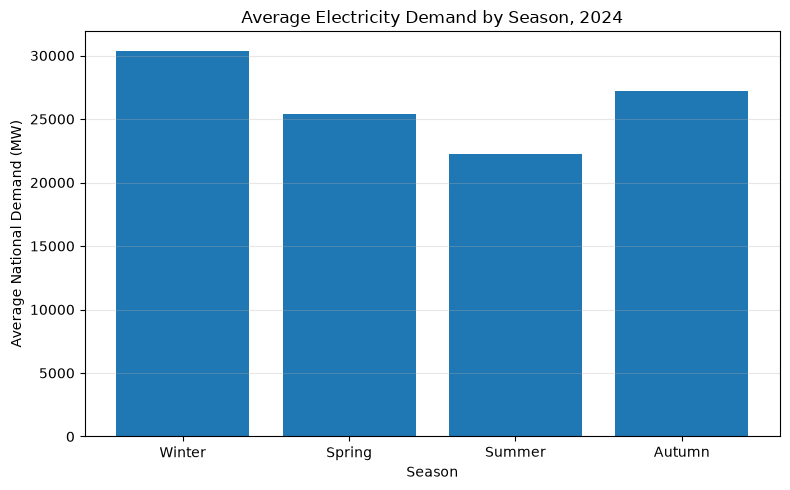

In [91]:
plt.figure(figsize=(8, 5))

plt.bar(
    seasonal_demand.index,
    seasonal_demand.values
)

plt.title("Average Electricity Demand by Season, 2024")
plt.xlabel("Season")
plt.ylabel("Average National Demand (MW)")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Finding:** Electricity demand varies substantially by season. Winter recorded the highest average National Demand at approximately 30,389 MW, followed by autumn at 27,189 MW and spring at 25,412 MW. Summer recorded the lowest average demand at approximately 22,210 MW. This supports the seasonal pattern observed in the monthly analysis, with demand generally higher during the colder parts of the year and lower during summer.

## 4. Key Findings and Conclusions

The analysis identified clear temporal patterns in Great Britain's electricity demand during 2024.

Average National Demand was highest during winter (approximately 30,389 MW) and lowest during summer (22,210 MW), demonstrating substantial seasonal variation. Demand also differed between weekdays and weekends, with average weekend demand approximately 11.8% lower than weekday demand.

The daily demand profiles showed recurring evening peaks around settlement period 38 (approximately 18:30–19:00), highlighting the importance of understanding peak demand periods when planning electricity generation, storage and system flexibility.

Overall, the findings demonstrate that electricity demand varies systematically across seasons, days of the week and times of day. These patterns provide useful insights for electricity system planning and demand forecasting.

**Limitation:** The analysis covers only 2024 and therefore cannot establish longer-term trends or account for year-to-year differences in weather and electricity consumption.